<a href="https://colab.research.google.com/github/83devansh/First-Sem-Projects/blob/main/Devu_Practical_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/evalsdataset.csv")

print(df.head())
print(df.shape)
print(df.columns)

   course_id  prof_id  score          rank     ethnicity  gender language  \
0          1        1    4.7  tenure track      minority  female  english   
1          2        1    4.1  tenure track      minority  female  english   
2          3        1    3.9  tenure track      minority  female  english   
3          4        1    4.8  tenure track      minority  female  english   
4          5        2    4.6       tenured  not minority    male  english   

   age  cls_perc_eval  cls_did_eval  ...   cls_credits bty_f1lower  \
0   36       55.81395            24  ...  multi credit           5   
1   36       68.80000            86  ...  multi credit           5   
2   36       60.80000            76  ...  multi credit           5   
3   36       62.60163            77  ...  multi credit           5   
4   59       85.00000            17  ...  multi credit           4   

  bty_f1upper bty_f2upper  bty_m1lower  bty_m1upper  bty_m2upper  bty_avg  \
0           7           6            2 

##**Q1 :Identify duplicate cases using prof_id**


In [ ]:
duplicates = df[df.duplicated(subset="prof_id", keep=False)]

print(duplicates)

     course_id  prof_id  score          rank     ethnicity  gender  \
0            1        1    4.7  tenure track      minority  female   
1            2        1    4.1  tenure track      minority  female   
2            3        1    3.9  tenure track      minority  female   
3            4        1    4.8  tenure track      minority  female   
4            5        2    4.6       tenured  not minority    male   
..         ...      ...    ...           ...           ...     ...   
458        459       93    4.5  tenure track  not minority    male   
459        460       94    3.5  tenure track      minority  female   
460        461       94    4.4  tenure track      minority  female   
461        462       94    4.4  tenure track      minority  female   
462        463       94    4.1  tenure track      minority  female   

        language  age  cls_perc_eval  cls_did_eval  ...   cls_credits  \
0        english   36       55.81395            24  ...  multi credit   
1        engl

### **average and standard deviation for age**

In [ ]:
print("Average Age:", df["age"].mean())
print("Standard Deviation:", df["age"].std())

Average Age: 48.365010799136066
Standard Deviation: 9.802742037864816


###**One observation for each instructor**

In [ ]:
df_one = df.drop_duplicates(subset="prof_id")

print("Total observations:", len(df_one))

Total observations: 94


###**Average and Standard Deviation after filtering**

In [ ]:
print("Average Age:", df_one["age"].mean())
print("Standard Deviation:", df_one["age"].std())

Average Age: 47.234042553191486
Standard Deviation: 10.268885598692291


##**Q2  Bar Chart: Lower-Division Courses and Evaluation**

In [ ]:
print(df["cls_level"].value_counts())

cls_level
upper    306
lower    157
Name: count, dtype: int64


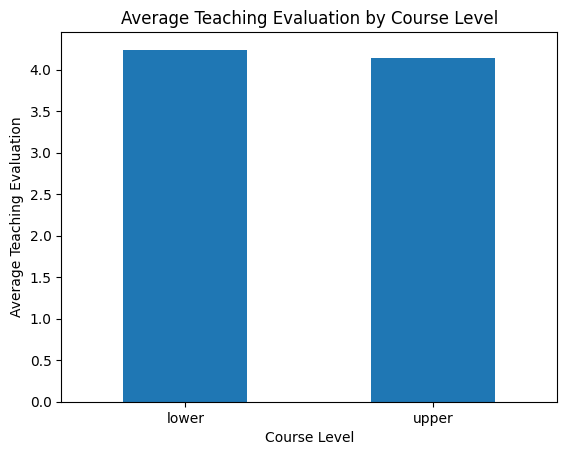

In [ ]:
average_eval = df.groupby("cls_level")["score"].mean()

average_eval.plot(kind="bar")

plt.xlabel("Course Level")
plt.ylabel("Average Teaching Evaluation")
plt.title("Average Teaching Evaluation by Course Level")
plt.xticks(rotation=0)
plt.show()

###**Conclusion**
**Compare the bars for the different course levels. The higher bar represents the course level with the higher average teaching evaluation.**

##**Q3.  Relationship Between Age and Teaching Evaluation**

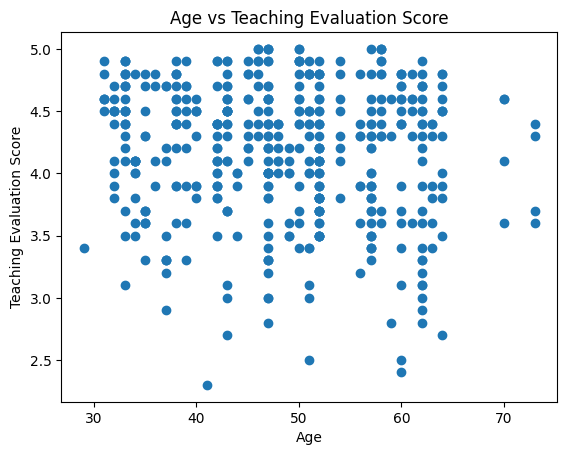

In [ ]:
plt.scatter(df["age"], df["score"])

plt.xlabel("Age")
plt.ylabel("Teaching Evaluation Score")
plt.title("Age vs Teaching Evaluation Score")

plt.show()

##**Q4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.**

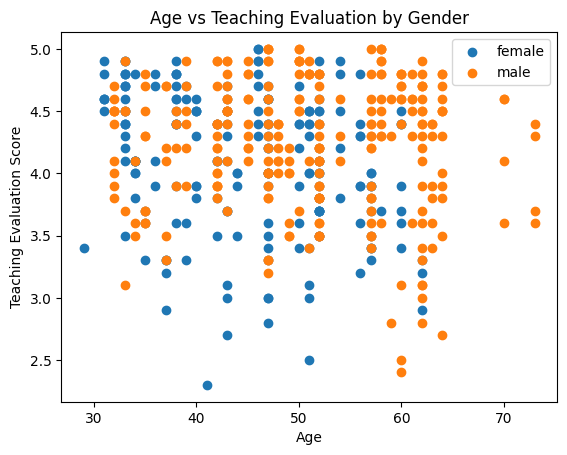

In [ ]:
for gender in df["gender"].unique():
    data = df[df["gender"] == gender]

    plt.scatter(
        data["age"],
        data["score"],
        label=gender
    )

plt.xlabel("Age")
plt.ylabel("Teaching Evaluation Score")
plt.title("Age vs Teaching Evaluation by Gender")
plt.legend()

plt.show()

##**Q5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.**

In [ ]:
print(df["rank"].unique())

['tenure track' 'tenured' 'teaching']


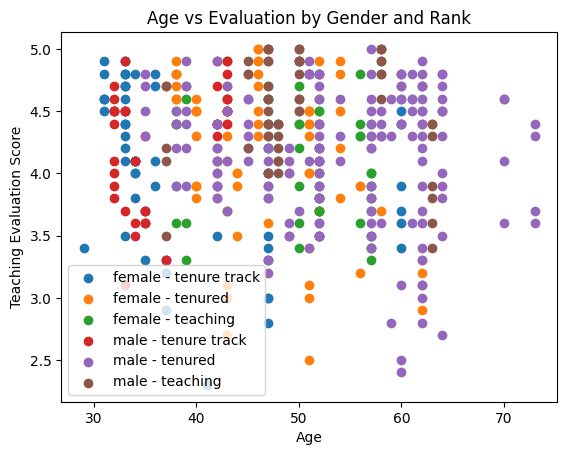

In [ ]:
for gender in df["gender"].unique():
    for rank in df["rank"].unique():

        data = df[
            (df["gender"] == gender) &
            (df["rank"] == rank)
        ]

        plt.scatter(
            data["age"],
            data["score"],
            label=f"{gender} - {rank}"
        )

plt.xlabel("Age")
plt.ylabel("Teaching Evaluation Score")
plt.title("Age vs Evaluation by Gender and Rank")
plt.legend()

plt.show()

**Conclusion
The scatterplot shows the relationship between professors' age and teaching evaluation scores, differentiated by gender and tenure/rank. Evaluation scores are spread across different age groups, indicating that age alone does not determine teaching evaluation scores. Different genders and ranks show variation in scores, while many professors receive relatively high evaluations (around 4.0–5.0). The scatterplot helps visualize patterns and compare evaluation scores across different groups.**